# Week 1 - Titanic data analysis (starter)

Steps: load -> clean -> summary statistics -> 5 charts -> 3 SQL questions.
Each step says what it does. The **Your insight** cells are for you to write in your own words after looking at each chart.

## 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

df = pd.read_csv("data/train.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [3]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Which columns have missing values?

In [4]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

**Notes:** `Age` is missing for 177 passengers, `Cabin` for 687 (too many to fill), `Embarked` for 2.

## 2. Clean the data

In [5]:
df_clean = df.copy()                     # keep the original untouched

# Age: fill missing values with the median age
df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())

# Embarked: only 2 missing, fill with the most common port
df_clean["Embarked"] = df_clean["Embarked"].fillna(df_clean["Embarked"].mode()[0])

# Cabin: about 77% missing, so drop the column
df_clean = df_clean.drop(columns=["Cabin"])

# Fix data types: these columns are categories, not free text
df_clean["Sex"] = df_clean["Sex"].astype("category")
df_clean["Embarked"] = df_clean["Embarked"].astype("category")

print("Missing values left:", df_clean.isna().sum().sum())
df_clean.dtypes

Missing values left: 0


PassengerId       int64
Survived          int64
Pclass            int64
Name                str
Sex            category
Age             float64
SibSp             int64
Parch             int64
Ticket              str
Fare            float64
Embarked       category
dtype: object

**Outliers:** a value is an outlier if it is more than 1.5 x IQR below Q1 or above Q3.

In [6]:
q1 = df_clean["Fare"].quantile(0.25)
q3 = df_clean["Fare"].quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print("Q1:", q1, "Q3:", q3, "IQR:", iqr, "upper fence:", upper)
print("Fares above the fence:", (df_clean["Fare"] > upper).sum())

Q1: 7.9104 Q3: 31.0 IQR: 23.0896 upper fence: 65.6344
Fares above the fence: 116


We keep these high fares: they are real first-class tickets, not mistakes.

## 3. Summary statistics

In [7]:
stats_table = df_clean[["Age", "Fare"]].agg(["mean", "median", "std"])
stats_table.loc["mode"] = df_clean[["Age", "Fare"]].mode().iloc[0]
stats_table

,Age,Fare
mean,29.361582,32.204208
median,28.000000,14.454200
std,13.019697,49.693429
mode,28.000000,8.050000


In [8]:
# Correlation between numeric columns (Survived is 0 or 1)
corr = df_clean[["Survived", "Pclass", "Age", "Fare", "SibSp", "Parch"]].corr()
corr["Survived"]

Survived    1.000000
Pclass     -0.338481
Age        -0.064910
Fare        0.257307
SibSp      -0.035322
Parch       0.081629
Name: Survived, dtype: float64

**Remember:** correlation does not mean causation. A higher fare goes with higher survival, but the fare itself did not save anyone: it is linked to class and cabin position.

## 4. Five charts

### Chart 1 - Histogram (age)

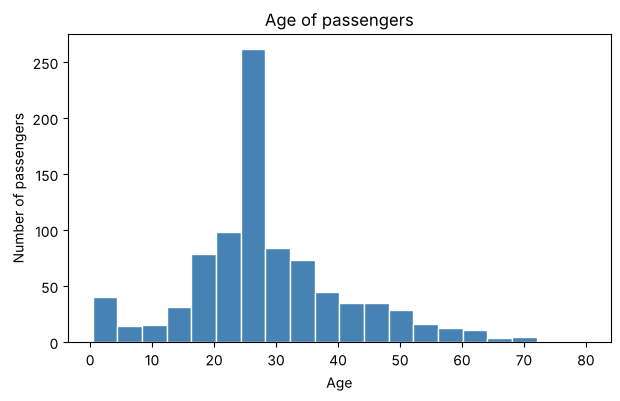

In [9]:
plt.figure(figsize=(7, 4))
plt.hist(df_clean["Age"], bins=20, color="steelblue", edgecolor="white")
plt.title("Age of passengers")
plt.xlabel("Age")
plt.ylabel("Number of passengers")
plt.show()

**Your insight (2-3 lines):**

_Write what you see. Hint: where is the peak? Is there a group of young children?_

### Chart 2 - Boxplot (fare by class)

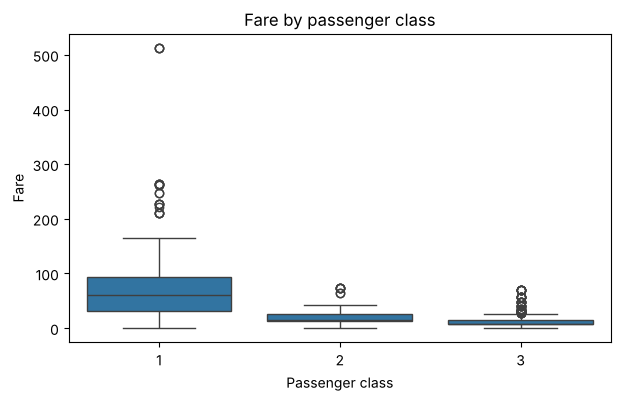

In [10]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df_clean, x="Pclass", y="Fare")
plt.title("Fare by passenger class")
plt.xlabel("Passenger class")
plt.ylabel("Fare")
plt.show()

**Your insight (2-3 lines):**

_Hint: compare the medians. Where are the dots above the boxes (outliers)?_

### Chart 3 - Correlation heatmap

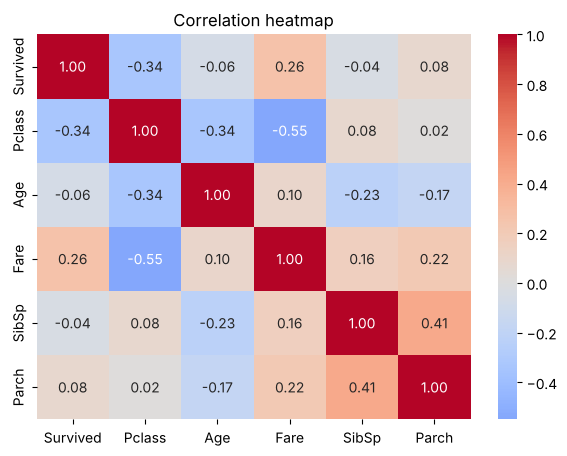

In [11]:
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

**Your insight (2-3 lines):**

_Hint: which column has the strongest link to Survived? Is it positive or negative?_

### Chart 4 - Bar chart (survival rate by class and sex)

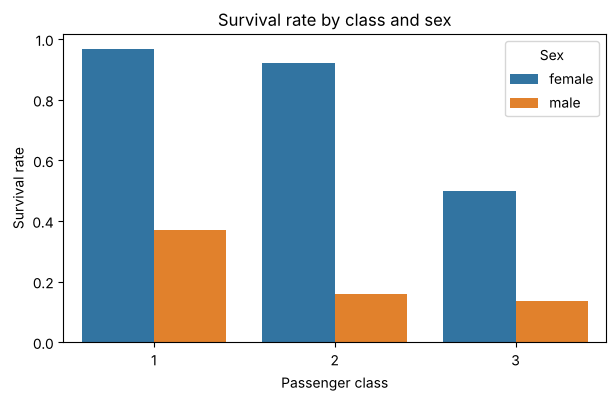

In [12]:
plt.figure(figsize=(7, 4))
sns.barplot(data=df_clean, x="Pclass", y="Survived", hue="Sex", errorbar=None)
plt.title("Survival rate by class and sex")
plt.xlabel("Passenger class")
plt.ylabel("Survival rate")
plt.show()

**Your insight (2-3 lines):**

_Hint: compare women and men inside each class._

### Chart 5 - Scatter plot (age vs fare)

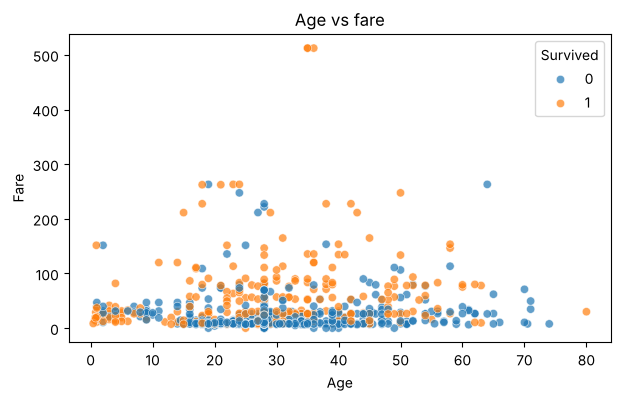

In [13]:
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df_clean, x="Age", y="Fare", hue="Survived", alpha=0.7)
plt.title("Age vs fare")
plt.show()

**Your insight (2-3 lines):**

_Hint: do the survivors have higher fares? Does age separate them?_

## 5. SQL

Load the cleaned data into SQLite, then ask three questions. The same queries are saved in `sql/queries.sql`.

In [14]:
con = sqlite3.connect(":memory:")                 # temporary database
df_clean.to_sql("titanic", con, index=False)

891

**Q1. Survival rate by class and sex**

In [15]:
q1 = '''
SELECT Pclass, Sex, COUNT(*) AS passengers,
       ROUND(AVG(Survived) * 100, 1) AS survival_pct
FROM titanic
GROUP BY Pclass, Sex
ORDER BY Pclass, Sex;
'''
pd.read_sql(q1, con)

,Pclass,Sex,passengers,survival_pct
0,1,female,94,96.8
1,1,male,122,36.9
2,2,female,76,92.1
3,2,male,108,15.7
4,3,female,144,50.0
5,3,male,347,13.5


Same in Pandas:

In [16]:
(df_clean.groupby(["Pclass", "Sex"], observed=True)["Survived"]
         .agg(passengers="count", survival_pct="mean").round(3))

passengers  survival_pct
Pclass Sex                             
1      female          94         0.968
       male           122         0.369
2      female          76         0.921
       male           108         0.157
3      female         144         0.500
       male           347         0.135

**Q2. Average fare and survival by port**

In [17]:
q2 = '''
SELECT Embarked, COUNT(*) AS passengers,
       ROUND(AVG(Fare), 2) AS avg_fare,
       ROUND(AVG(Survived) * 100, 1) AS survival_pct
FROM titanic
GROUP BY Embarked
ORDER BY survival_pct DESC;
'''
pd.read_sql(q2, con)

,Embarked,passengers,avg_fare,survival_pct
0,C,168,59.95,55.4
1,Q,77,13.28,39.0
2,S,646,27.24,33.9


**Q3. The 5 highest fares paid by survivors**

In [18]:
q3 = '''
SELECT Name, Pclass, Fare
FROM titanic
WHERE Survived = 1
ORDER BY Fare DESC
LIMIT 5;
'''
pd.read_sql(q3, con)

,Name,Pclass,Fare
0,"Ward, Miss. Anna",1,512.3292
1,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292
2,"Lesurer, Mr. Gustave J",1,512.3292
3,"Fortune, Miss. Mabel Helen",1,263.0000
4,"Fortune, Miss. Alice Elizabeth",1,263.0000


## Your conclusions

_Write 3-4 lines in your own words: who was most likely to survive and why do you think so?_

## Practice (do these yourself)

1. Fill missing ages using the median of each class (hint: `groupby("Pclass")["Age"].transform("median")`).
2. Add a chart: a countplot of passengers by `Embarked`.
3. Write a 4th SQL query: average age of survivors vs non-survivors.